In [16]:
pip install torch torch-geometric rdkit pandas numpy

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com

[notice] A new release of pip is available: 23.3.2 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, random_split
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from rdkit import Chem

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# ============================================
# 1. CUSTOM PYTORCH GEOMETRIC DATASET
# ============================================

class MoleculeDataset(Dataset):
    """Parses SMILES from CSV and converts them into PyTorch Geometric Data objects."""
    
    def __init__(self, csv_file, smiles_col="SMILES", target_col="pIC50"):
        df = pd.read_csv(csv_file)
        self.smiles = df[smiles_col].values
        self.labels = df[target_col].values

    def __len__(self):
        return len(self.smiles)

    def _get_atom_features(self, atom):
        """Extract basic node features from RDKit atom."""
        # One-hot encoding for common elements + atomic number
        atomic_num = atom.GetAtomicNum()
        degree = atom.GetDegree()
        aromatic = 1.0 if atom.GetIsAromatic() else 0.0
        return [atomic_num, degree, aromatic]

    def __getitem__(self, idx):
        smiles = self.smiles[idx]
        target = self.labels[idx]

        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            raise ValueError(f"Invalid SMILES string encountered: {smiles}")

        # 1. Node Features (x) -> Shape: [num_nodes, num_node_features]
        node_features = [self._get_atom_features(atom) for atom in mol.GetAtoms()]
        x = torch.tensor(node_features, dtype=torch.float)

        # 2. Edge Index (Adjacency Matrix COO format) -> Shape: [2, num_edges]
        edge_indices = []
        for bond in mol.GetBonds():
            start, end = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
            # Undirected graph requires edges in both directions
            edge_indices.append([start, end])
            edge_indices.append([end, start])

        if len(edge_indices) == 0:
            # Handle single-atom molecules (e.g., methane or metal ions)
            edge_index = torch.empty((2, 0), dtype=torch.long)
        else:
            edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

        # 3. Label (y) -> Shape: [1]
        y = torch.tensor([target], dtype=torch.float)

        return Data(x=x, edge_index=edge_index, y=y)


# ============================================
# 2. MODEL DEFINITION
# ============================================

class GCNModel(nn.Module):
    """PyTorch equivalent of DeepChem's GraphConvModel architecture."""
    
    def __init__(self, in_channels=3, hidden_channels=64, out_channels=1):
        super(GCNModel, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.fc = nn.Linear(hidden_channels, out_channels)
        self.relu = nn.ReLU()

    def forward(self, x, edge_index, batch):
        # Layer 1: Graph Convolution
        x = self.conv1(x, edge_index)
        x = self.relu(x)

        # Layer 2: Graph Convolution
        x = self.conv2(x, edge_index)
        x = self.relu(x)

        # Global Pooling: Aggregate node embeddings into a single graph embedding
        x = global_mean_pool(x, batch)

        # Output Regression Head
        out = self.fc(x)
        return out


# ============================================
# 3. DATA LOADING & SPLITTING
# ============================================

DATA_FILE = "/data/Zira/USP5_chemprop.csv"

# Load full dataset
full_dataset = MoleculeDataset(DATA_FILE)

# Perform 70 / 29 / 1 Train / Valid / Test split
total_len = len(full_dataset)
train_len = int(0.70 * total_len)
valid_len = int(0.29 * total_len)
test_len = total_len - train_len - valid_len

train_dataset, valid_dataset, test_dataset = random_split(
    full_dataset, 
    [train_len, valid_len, test_len],
    generator=torch.Generator().manual_seed(42)
)

print(f"Training set: {len(train_dataset)}")
print(f"Validation set: {len(valid_dataset)}")
print(f"Testing set: {len(test_dataset)}")

# PyTorch Geometric DataLoaders handle graph batching automatically
train_loader = DataLoader(train_dataset, batch_size=10, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=10, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=10, shuffle=False)


# ============================================
# 4. TRAINING LOOP (5 EPOCHS)
# ============================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = GCNModel(in_channels=3, hidden_channels=64, out_channels=1).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

print(f"\nMemulai test training 5 epoch pada target device: {device}...")

model.train()
for epoch in range(1, 6):
    total_loss = 0.0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        
        # Forward pass
        out = model(batch.x, batch.edge_index, batch.batch)
        loss = criterion(out.squeeze(-1), batch.y.squeeze(-1))
        
        # Backward pass & update weights
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * batch.num_graphs

    epoch_loss = total_loss / len(train_dataset)
    print(f"Epoch {epoch}/5 - Train Loss (MSE): {epoch_loss:.4f}")

print("\nTEST TRAINING BERHASIL!")


# ============================================
# 5. VALIDATION PREDICTION
# ============================================

model.eval()
predictions = []

with torch.no_grad():
    for batch in valid_loader:
        batch = batch.to(device)
        out = model(batch.x, batch.edge_index, batch.batch)
        predictions.extend(out.squeeze(-1).cpu().numpy().tolist())

predictions = np.array(predictions)

print("Jumlah prediksi validation:", len(predictions))
print("Contoh prediksi:", predictions[:5])

Training set: 82
Validation set: 34
Testing set: 2

Memulai test training 5 epoch pada target device: cuda...
Epoch 1/5 - Train Loss (MSE): 21.6670
Epoch 2/5 - Train Loss (MSE): 15.5695
Epoch 3/5 - Train Loss (MSE): 10.2128
Epoch 4/5 - Train Loss (MSE): 5.6013
Epoch 5/5 - Train Loss (MSE): 2.7435

TEST TRAINING BERHASIL!
Jumlah prediksi validation: 34
Contoh prediksi: [4.42552662 4.1941328  4.31412601 4.27702141 4.27986526]


OPTIMASI EPOCH GRAPHCONVMODEL USP5 (PyTorch Geometric)
Dataset: /data/Zira/USP5_chemprop.csv
Output: /data/Zira/Optimasi_Epoch/Run_20261022_090424_512400
Learning rate: 0.001
Batch size: 10
Device: cuda

DATASET INFORMATION
Total: 118
Training: 82
Validation: 34
Testing: 2

EVALUASI EPOCH: 100
Loss : 1.8008
MAE  : 1.0026
RMSE : 1.2892
R2   : 0.0471
MODEL TERBAIK DIPERBARUI!

EVALUASI EPOCH: 200
Loss : 1.6697
MAE  : 1.0376
RMSE : 1.2838
R2   : 0.0550
MODEL TERBAIK DIPERBARUI!

EVALUASI EPOCH: 300
Loss : 1.5690
MAE  : 1.0392
RMSE : 1.3012
R2   : 0.0293

EVALUASI EPOCH: 400
Loss : 1.5057
MAE  : 1.0450
RMSE : 1.2577
R2   : 0.0931
MODEL TERBAIK DIPERBARUI!

EVALUASI EPOCH: 500
Loss : 1.5793
MAE  : 1.0309
RMSE : 1.3294
R2   : -0.0132

EVALUASI EPOCH: 600
Loss : 1.4450
MAE  : 1.0235
RMSE : 1.2334
R2   : 0.1278
MODEL TERBAIK DIPERBARUI!

EVALUASI EPOCH: 700
Loss : 1.4594
MAE  : 1.0320
RMSE : 1.2295
R2   : 0.1333
MODEL TERBAIK DIPERBARUI!

EVALUASI EPOCH: 800
Loss : 1.4726
MAE  : 1.0082
RMSE : 

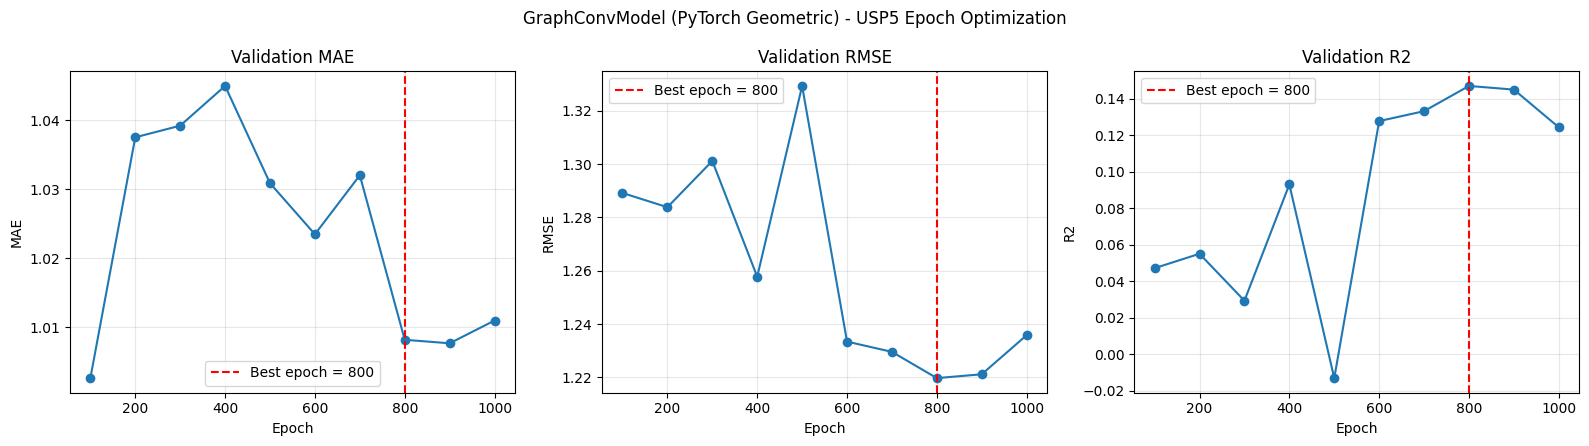


OPTIMASI EPOCH SELESAI!
Hasil tersimpan di: /data/Zira/Optimasi_Epoch/Run_20261022_090424_512400


In [5]:
# ============================================================
# OPTIMASI EPOCH GRAPHCONVMODEL USP5 (PyTorch Version)
# 100 - 1000 EPOCH
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

import torch
import torch.nn as nn
from torch.utils.data import Dataset, random_split
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from rdkit import Chem

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# 1. PENGATURAN
# ============================================================

SEED = 42
LEARNING_RATE = 0.001
BATCH_SIZE = 10

MAX_EPOCH = 1000
STEP_EPOCH = 100

DATA_FILE = "/data/Zira/USP5_chemprop.csv"
BASE_DIR = "/data/Zira/Optimasi_Epoch"

# Folder khusus untuk percobaan ini
RUN_DIR = os.path.join(
    BASE_DIR,
    "Run_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)

BEST_MODEL_DIR = os.path.join(RUN_DIR, "best_model")
os.makedirs(BEST_MODEL_DIR, exist_ok=True)

# Set random seeds for reproducibility
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("OPTIMASI EPOCH GRAPHCONVMODEL USP5 (PyTorch Geometric)")
print("=" * 60)
print("Dataset:", DATA_FILE)
print("Output:", RUN_DIR)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Device:", device)

# ============================================================
# 2. CUSTOM PYTORCH GEOMETRIC DATASET
# ============================================================

class MoleculeDataset(Dataset):
    """Parses SMILES from CSV and converts them into PyTorch Geometric Data objects."""
    
    def __init__(self, csv_file, smiles_col="SMILES", target_col="pIC50"):
        df = pd.read_csv(csv_file)
        self.smiles = df[smiles_col].values
        self.labels = df[target_col].values

    def __len__(self):
        return len(self.smiles)

    def _get_atom_features(self, atom):
        """Extract basic node features from RDKit atom."""
        atomic_num = atom.GetAtomicNum()
        degree = atom.GetDegree()
        aromatic = 1.0 if atom.GetIsAromatic() else 0.0
        return [atomic_num, degree, aromatic]

    def __getitem__(self, idx):
        smiles = self.smiles[idx]
        target = self.labels[idx]

        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            raise ValueError(f"Invalid Smiles string: {SMILES}")

        # Node Features (x)
        node_features = [self._get_atom_features(atom) for atom in mol.GetAtoms()]
        x = torch.tensor(node_features, dtype=torch.float)

        # Edge Index (COO Adjacency Matrix)
        edge_indices = []
        for bond in mol.GetBonds():
            start, end = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
            edge_indices.append([start, end])
            edge_indices.append([end, start])

        if len(edge_indices) == 0:
            edge_index = torch.empty((2, 0), dtype=torch.long)
        else:
            edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

        # Target (y)
        y = torch.tensor([target], dtype=torch.float)

        return Data(x=x, edge_index=edge_index, y=y)

# Load dataset and perform 70 / 29 / 1 Split
full_dataset = MoleculeDataset(DATA_FILE)

total_len = len(full_dataset)
train_len = int(0.70 * total_len)
valid_len = int(0.29 * total_len)
test_len = total_len - train_len - valid_len

train_dataset, valid_dataset, test_dataset = random_split(
    full_dataset, 
    [train_len, valid_len, test_len],
    generator=torch.Generator().manual_seed(SEED)
)

print("\nDATASET INFORMATION")
print("Total:", total_len)
print("Training:", len(train_dataset))
print("Validation:", len(valid_dataset))
print("Testing:", len(test_dataset))

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# ============================================================
# 3. MODEL DEFINITION
# ============================================================

class GraphConvModelPyTorch(nn.Module):
    def __init__(self, in_channels=3, hidden_channels=64, out_channels=1):
        super(GraphConvModelPyTorch, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.fc = nn.Linear(hidden_channels, out_channels)
        self.relu = nn.ReLU()

    def forward(self, x, edge_index, batch):
        x = self.conv1(x, edge_index)
        x = self.relu(x)
        x = self.conv2(x, edge_index)
        x = self.relu(x)
        x = global_mean_pool(x, batch)
        return self.fc(x)

model = GraphConvModelPyTorch(in_channels=3, hidden_channels=64, out_channels=1).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()

results = []
best_rmse = float("inf")
best_epoch = None

# ============================================================
# 4. OPTIMASI EPOCH (100 - 1000)
# ============================================================

total_epochs_trained = 0

for step in range(STEP_EPOCH, MAX_EPOCH + 1, STEP_EPOCH):

    print("\n" + "=" * 60)
    print(f"EVALUASI EPOCH: {step}")
    print("=" * 60)

    # Train for STEP_EPOCH (100) additional epochs
    model.train()
    for sub_epoch in range(STEP_EPOCH):
        total_epochs_trained += 1
        running_loss = 0.0
        
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            
            out = model(batch.x, batch.edge_index, batch.batch)
            loss = criterion(out.squeeze(-1), batch.y.squeeze(-1))
            
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * batch.num_graphs

    current_train_loss = running_loss / len(train_dataset)

    # Validation Prediction
    model.eval()
    y_true, y_pred = [], []
    
    with torch.no_grad():
        for batch in valid_loader:
            batch = batch.to(device)
            out = model(batch.x, batch.edge_index, batch.batch)
            y_pred.extend(out.squeeze(-1).cpu().numpy())
            y_true.extend(batch.y.squeeze(-1).cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Evaluation Metrics
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results.append({
        "Epoch": step,
        "Loss": float(current_train_loss),
        "MAE": float(mae),
        "RMSE": float(rmse),
        "R2": float(r2)
    })

    print(f"Loss : {current_train_loss:.4f}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R2   : {r2:.4f}")

    # Save best model checkpoint
    if rmse < best_rmse:
        best_rmse = rmse
        best_epoch = step

        best_checkpoint_path = os.path.join(BEST_MODEL_DIR, "best_model.pt")
        torch.save({
            'epoch': step,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_rmse': best_rmse
        }, best_checkpoint_path)

        print("MODEL TERBAIK DIPERBARUI!")

    # Save CSV results after every step
    pd.DataFrame(results).to_csv(
        os.path.join(RUN_DIR, "Epoch_Results.csv"),
        index=False
    )

# ============================================================
# 5. HASIL AKHIR
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("HASIL OPTIMASI EPOCH GRAPHCONVMODEL (PYTORCH)")
print("=" * 60)

print(results_df.round(4).to_string(index=False))

print("\n" + "=" * 60)
print("BEST EPOCH")
print("=" * 60)

print("Epoch terbaik :", best_epoch)
print("Validation RMSE:", round(best_rmse, 4))
print("Checkpoint:", os.path.join(BEST_MODEL_DIR, "best_model.pt"))

# ============================================================
# 6. GRAFIK OPTIMASI
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

metrics = ["MAE", "RMSE", "R2"]

for ax, metric in zip(axes, metrics):
    ax.plot(
        results_df["Epoch"],
        results_df[metric],
        marker="o"
    )

    ax.axvline(
        best_epoch,
        color="red",
        linestyle="--",
        label=f"Best epoch = {best_epoch}"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric)
    ax.set_title(f"Validation {metric}")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("GraphConvModel (PyTorch Geometric) - USP5 Epoch Optimization")
plt.tight_layout()

plt.savefig(
    os.path.join(RUN_DIR, "Epoch_Optimization.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nOPTIMASI EPOCH SELESAI!")
print("Hasil tersimpan di:", RUN_DIR)